In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import datetime as dt

In [2]:
df = pd.read_csv("uber.csv")

df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")

df.head()

Dataset Shape: (200000, 9)

First Five Records:


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
df.drop(
    columns=['Unnamed: 0', 'key'],
    inplace=True,
    errors='ignore'
)

df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        200000 non-null  float64
 1   pickup_datetime    200000 non-null  str    
 2   pickup_longitude   200000 non-null  float64
 3   pickup_latitude    200000 non-null  float64
 4   dropoff_longitude  199999 non-null  float64
 5   dropoff_latitude   199999 non-null  float64
 6   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 10.7 MB


In [6]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [7]:
df.dropna(how='any', inplace=True)

df.reset_index(drop=True, inplace=True)

print("Dataset Shape After Removing Missing Values:")

print(df.shape)

Dataset Shape After Removing Missing Values:
(199999, 7)


In [8]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000
mean,11.359892,-72.527631,39.935881,-72.525292,39.923890,1.684543
std,9.901760,11.437815,7.720558,13.117408,6.794829,1.385995
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


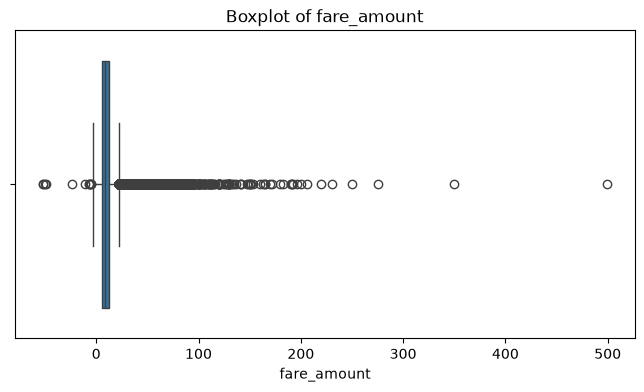

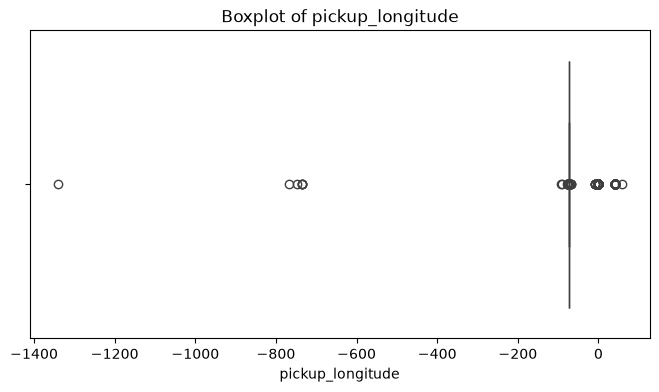

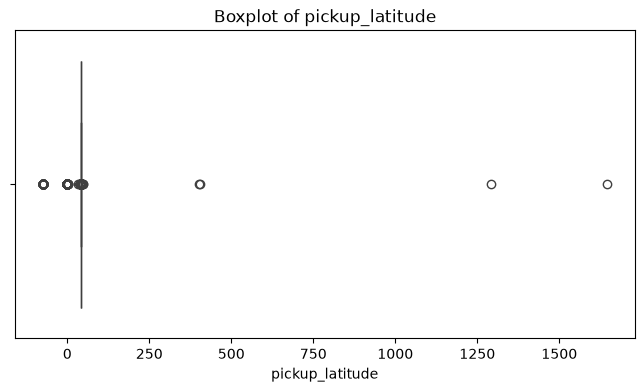

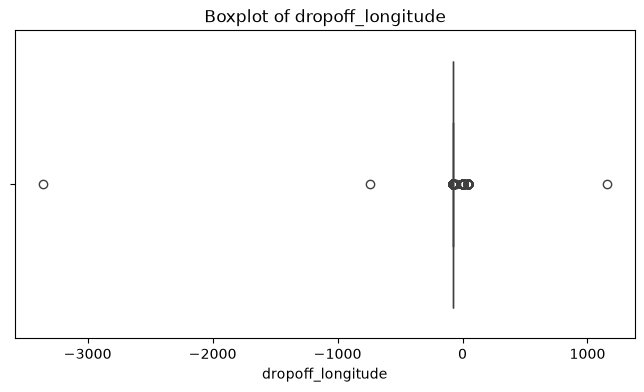

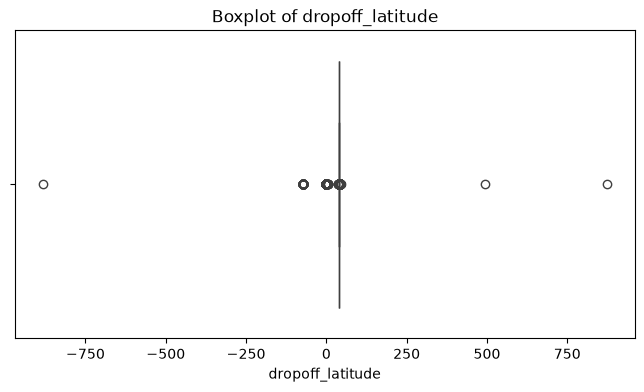

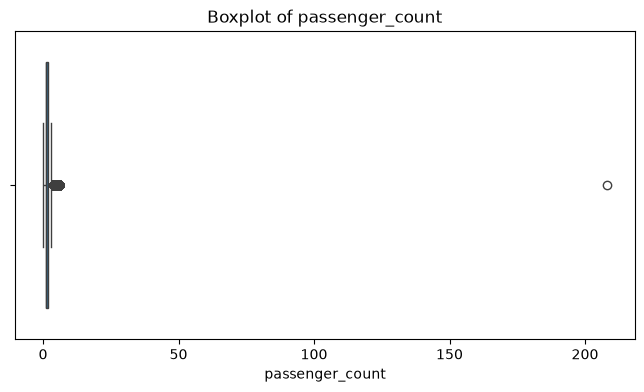

In [9]:
for col in df.select_dtypes(include=['number']).columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=col)

    plt.title("Boxplot of " + col)

    plt.show()

In [10]:
df = df[
    (df['pickup_latitude'] > -90) &
    (df['pickup_latitude'] < 90) &
    (df['dropoff_latitude'] > -90) &
    (df['dropoff_latitude'] < 90) &
    (df['pickup_longitude'] > -180) &
    (df['pickup_longitude'] < 180) &
    (df['dropoff_longitude'] > -180) &
    (df['dropoff_longitude'] < 180) &
    (df['fare_amount'] > 0) &
    (df['passenger_count'] > 0) &
    (df['passenger_count'] < 50)
].copy()

df.reset_index(drop=True, inplace=True)

df.shape

(199256, 7)

In [11]:
from math import radians, sin, cos, asin, sqrt

In [12]:
def distance(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2]
    )

    diff_lon = lon2 - lon1

    diff_lat = lat2 - lat1

    km = 2 * 6371 * np.arcsin(
        np.sqrt(
            np.sin(diff_lat / 2) ** 2 +
            np.cos(lat1) * np.cos(lat2) *
            np.sin(diff_lon / 2) ** 2
        )
    )

    return km

In [13]:
temp = distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

print(temp.head())

0    1.683323
1    2.457590
2    5.036377
3    1.661683
4    4.475450
dtype: float64


In [14]:
df['Distance'] = temp

df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,1.683323
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,2.457590
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,5.036377
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,1.661683
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,4.475450


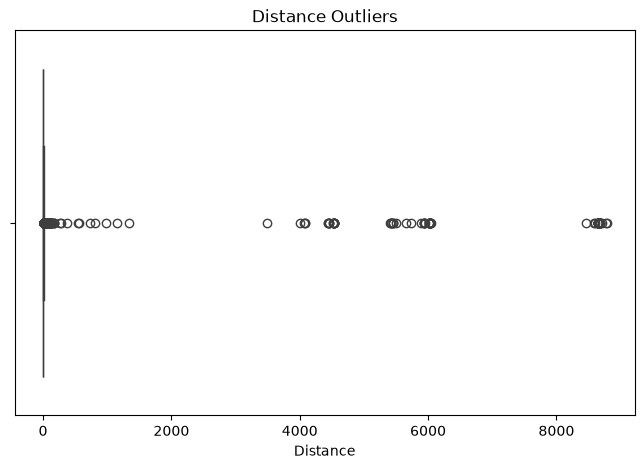

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Distance')

plt.title("Distance Outliers")

plt.show()

In [16]:
df = df[
    (df['Distance'] > 0) &
    (df['Distance'] < 200)
].copy()

df.reset_index(drop=True, inplace=True)

df.shape

(193221, 8)

In [17]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    errors='coerce'
)

df.dropna(subset=['pickup_datetime'], inplace=True)

df['week_day'] = df['pickup_datetime'].dt.day_name()

df['Year'] = df['pickup_datetime'].dt.year

df['Month'] = df['pickup_datetime'].dt.month

df['Hour'] = df['pickup_datetime'].dt.hour

df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Distance,week_day,Year,Month,Hour
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,Thursday,2015,5,19
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,Friday,2009,7,20
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,Monday,2009,8,21
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,Friday,2009,6,8
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,Thursday,2014,8,17


In [18]:
df.drop(
    columns=[
        'pickup_datetime',
        'pickup_latitude',
        'pickup_longitude',
        'dropoff_latitude',
        'dropoff_longitude'
    ],
    inplace=True
)

df.head()

,fare_amount,passenger_count,Distance,week_day,Year,Month,Hour
0,7.5,1,1.683323,Thursday,2015,5,19
1,7.7,1,2.457590,Friday,2009,7,20
2,12.9,1,5.036377,Monday,2009,8,21
3,5.3,3,1.661683,Friday,2009,6,8
4,16.0,5,4.475450,Thursday,2014,8,17


In [19]:
def convert_week_day(day):

    if day in ['Monday', 'Tuesday', 'Wednesday', 'Thursday']:

        return 0

    return 1


df['week_day'] = df['week_day'].apply(convert_week_day)

df.head()

,fare_amount,passenger_count,Distance,week_day,Year,Month,Hour
0,7.5,1,1.683323,0,2015,5,19
1,7.7,1,2.457590,1,2009,7,20
2,12.9,1,5.036377,0,2009,8,21
3,5.3,3,1.661683,1,2009,6,8
4,16.0,5,4.475450,0,2014,8,17


In [20]:
def convert_hour(hour):

    if 5 <= hour <= 12:

        return 1

    elif 12 < hour <= 17:

        return 2

    elif 17 < hour < 24:

        return 3

    return 0


df['Hour'] = df['Hour'].apply(convert_hour)

df.head()

,fare_amount,passenger_count,Distance,week_day,Year,Month,Hour
0,7.5,1,1.683323,0,2015,5,3
1,7.7,1,2.457590,1,2009,7,3
2,12.9,1,5.036377,0,2009,8,3
3,5.3,3,1.661683,1,2009,6,1
4,16.0,5,4.475450,0,2014,8,2


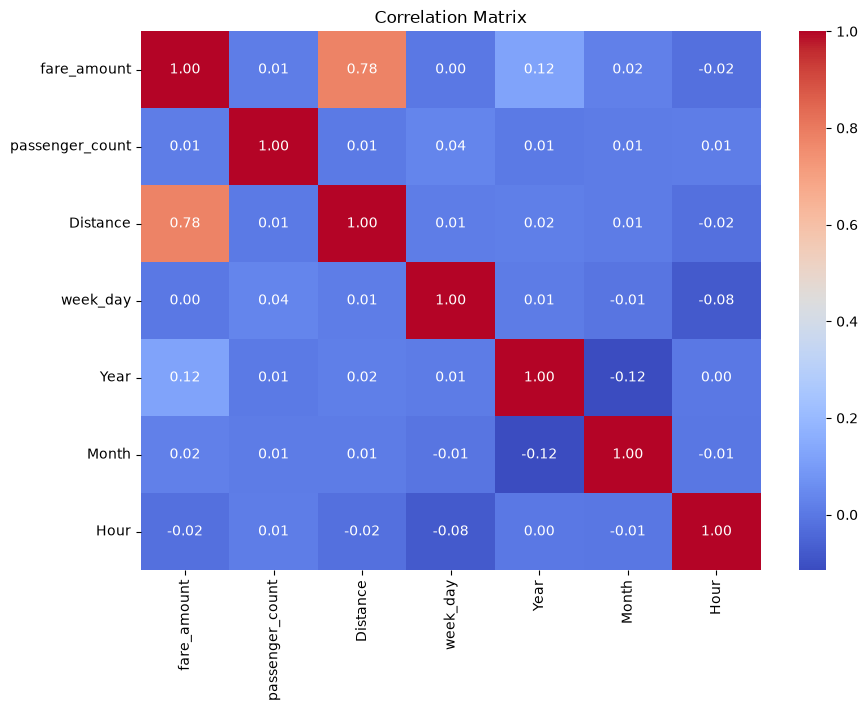

In [21]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.show()

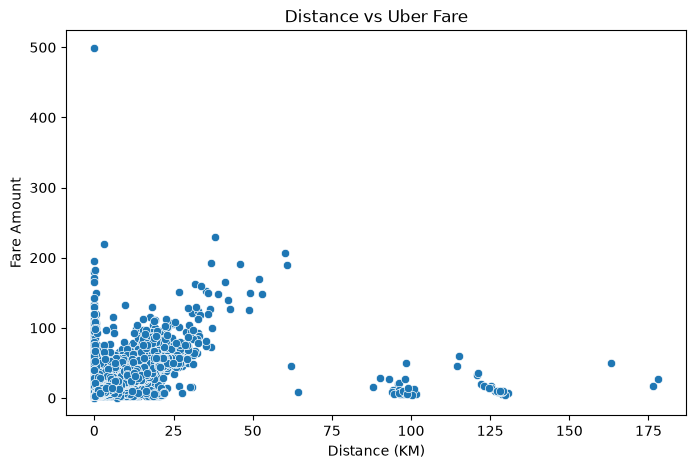

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df['Distance'],
    y=df['fare_amount']
)

plt.xlabel("Distance (KM)")

plt.ylabel("Fare Amount")

plt.title("Distance vs Uber Fare")

plt.show()

In [23]:
x = df[
    [
        'Distance',
        'passenger_count',
        'week_day',
        'Year',
        'Month',
        'Hour'
    ]
]

y = df['fare_amount']

print("Independent Variables:")

print(x.head())

print("\nDependent Variable:")

print(y.head())

Independent Variables:
   Distance  passenger_count  week_day  Year  Month  Hour
0  1.683323                1         0  2015      5     3
1  2.457590                1         1  2009      7     3
2  5.036377                1         0  2009      8     3
3  1.661683                3         1  2009      6     1
4  4.475450                5         0  2014      8     2

Dependent Variable:
0     7.5
1     7.7
2    12.9
3     5.3
4    16.0
Name: fare_amount, dtype: float64


In [24]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.25,
    random_state=10
)

print("Training Data:", x_train.shape)

print("Testing Data:", x_test.shape)

Training Data: (144915, 6)
Testing Data: (48306, 6)


In [25]:
from sklearn.preprocessing import StandardScaler

std_x = StandardScaler()

x_train_scaled = std_x.fit_transform(x_train)

x_test_scaled = std_x.transform(x_test)

In [26]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

def evaluate_model(model, x_train, x_test, y_train, y_test):

    model.fit(x_train, y_train)

    y_pred = model.predict(x_test)

    r_squared = r2_score(y_test, y_pred)

    RMSE = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    MAE = mean_absolute_error(y_test, y_pred)

    print("R-squared:", r_squared)

    print("RMSE:", RMSE)

    print("MAE:", MAE)

    return y_pred, r_squared, RMSE, MAE

In [27]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

print("Linear Regression Results:")

lr_pred, lr_r2, lr_rmse, lr_mae = evaluate_model(
    lr_model,
    x_train_scaled,
    x_test_scaled,
    y_train,
    y_test
)

Linear Regression Results:
R-squared: 0.6158985495609698
RMSE: 6.035944664240169
MAE: 2.5773740203418636


In [28]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=10,
    n_jobs=-1
)

print("Random Forest Regression Results:")

rf_pred, rf_r2, rf_rmse, rf_mae = evaluate_model(
    rf_model,
    x_train,
    x_test,
    y_train,
    y_test
)

Random Forest Regression Results:
R-squared: 0.7661583129347007
RMSE: 4.709591553024401
MAE: 2.2421710981382574


In [29]:
comparison = pd.DataFrame({

    'Model': [
        'Linear Regression',
        'Random Forest Regression'
    ],

    'R2 Score': [
        lr_r2,
        rf_r2
    ],

    'RMSE': [
        lr_rmse,
        rf_rmse
    ],

    'MAE': [
        lr_mae,
        rf_mae
    ]

})

print("Model Performance Comparison:")

comparison

Model Performance Comparison:


,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.615899,6.035945,2.577374
1,Random Forest Regression,0.766158,4.709592,2.242171


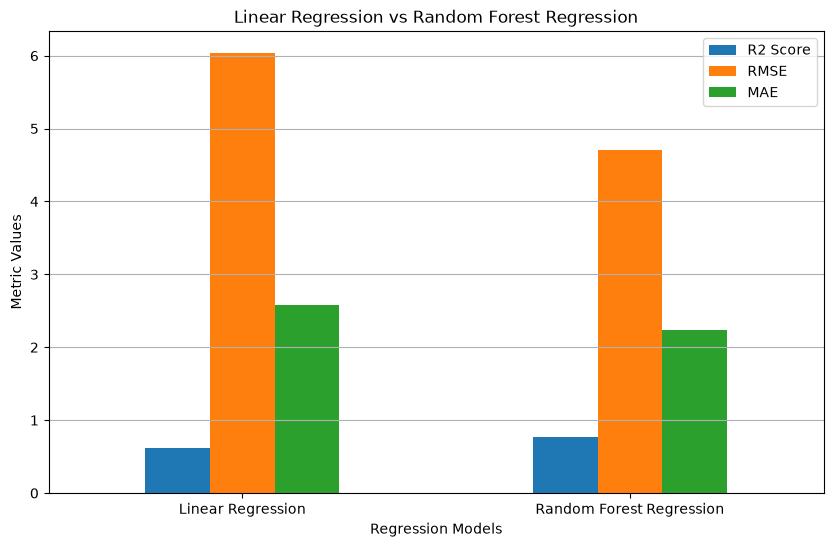

In [30]:
comparison.set_index('Model')[['R2 Score', 'RMSE', 'MAE']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Linear Regression vs Random Forest Regression")

plt.ylabel("Metric Values")

plt.xlabel("Regression Models")

plt.xticks(rotation=0)

plt.grid(axis='y')

plt.show()